# 02 — Feature robustness, redundancy and a first predictive model

> **Dataset:** these results come from the **public TCIA Soft-tissue-Sarcoma** collection (51 patients), *not* from
> the STEREOSARC / Centre François Baclesse patients. Download and citation:
> https://www.cancerimagingarchive.net/collection/soft-tissue-sarcoma/ (doi:10.7937/K9/TCIA.2015.7GO2GSKS, CC BY 3.0).
> See the [README](../README.md#dataset-used-here-tcia-soft-tissue-sarcoma) for how to download it with `scripts/download_sts.py`.

Notebook 01 turned each CT + contour into **107 numbers** (radiomic features). This notebook asks two questions:

1. **Which of those numbers can we trust?** A feature that changes a lot when the contour moves by 1 mm, or when
   we change a processing setting, measures the *pipeline* more than the *patient*. We measure this with the
   **ICC** (intra-class correlation) and keep only the stable features. This is deliverable 5 of the project
   ("first analysis of the variability and robustness of the parameters").
2. **Do the trustworthy features carry any signal?** On the public dataset we have a real outcome: whether the
   patient later developed **lung metastases** (`LungMets`). We check, feature by feature and then with a small
   cross-validated model, whether the CT radiomics of the primary tumour predicts it.

| Section | Question | Main output |
|---|---|---|
| 0 | What data goes in? | feature table + labels |
| 1 | Are the scans acquired the same way? (QC) | acquisition-parameter table |
| 2 | Which features are stable? | ICC per feature, list of robust features |
| 3 | Which features are redundant? | correlation clusters, one representative per cluster |
| 4 | Does any single feature separate the two groups? | AUC + corrected p-value per feature |
| 5 | Does a multivariable model do better than tumour size? | cross-validated AUC, permutation test |
| 6 | What does this mean for STEREOSARC? | limits and next steps |

> **Before running:** the features are pre-computed by `scripts/extract_cohort.py` (≈ 20 min with 4 workers)
> and stored in `outputs/features_cohort.csv`. The notebook only reads that file; it runs in ≈ 5 min
> (most of it is the repeated cross-validation and the permutation test of section 5).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, false_discovery_control
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_val_predict, permutation_test_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

from src.clinical import load_clinical
from src.quality_control import acquisition_table
from src.robustness import icc_table

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"

## 0. Inputs

**Features** (`outputs/features_cohort.csv`): one row per *(patient, ROI, condition)*. The *condition* says how the
features were computed:

| condition | ROI | what changes compared with `baseline` | purpose |
|---|---|---|---|
| `baseline` | GTV_Mass | nothing: settings of `config/pyradiomics_params.yaml` (bin width 25 HU, 1 mm voxels) | reference values |
| `erode` / `dilate` | GTV_Mass | contour shrunk / grown by 1 voxel (≈ 1 mm) in each slice | simulates a second person drawing the contour |
| `bw15` / `bw40` | GTV_Mass | grey-level bin width 15 or 40 HU instead of 25 | sensitivity to a processing choice |
| `baseline` | GTV_Edema | tumour + surrounding edema (32 patients only) | kept for later |

**Labels** (`data/clinical/INFOclinical_STS.xlsx`): `LungMets` = 1 if the patient developed lung metastases during
follow-up. This is the label used in the original publication (Vallières et al., 2015).

In [2]:
long = pd.read_csv(OUT / "features_cohort.csv")
FEATS = [c for c in long.columns if c.startswith("original_")]
clin = load_clinical()

print(f"{long.PatientID.nunique()} patients, {len(FEATS)} features")
print(long.groupby(["ROI", "condition"]).size().rename("rows").to_string())
print()
print(clin.LungMets.value_counts().rename({0: "no lung mets", 1: "lung mets"}).to_string())

51 patients, 107 features
ROI        condition
GTV_Edema  baseline     32
GTV_Mass   baseline     51
           bw15         51
           bw40         51
           dilate       51
           erode        51

LungMets
no lung mets    32
lung mets       19


**What the output shows:** every patient has the 5 GTV_Mass conditions (51 rows each) and 32 also have an
edema contour. The outcome is **unbalanced and small**: 19 patients with lung metastases versus 32 without.
With 19 events, any model must stay very simple (rule of thumb: ≤ 1 feature per 10 events → 1–2 features),
otherwise it will learn noise.

## 1. Quality control: how were the scans acquired?

Radiomic features depend on the **acquisition protocol** (scanner, tube voltage, reconstruction kernel, slice
thickness). If two groups of patients were scanned differently, a model can learn the protocol instead of the
biology. So before any statistics we read the protocol from the DICOM header of each scan
(`src/quality_control.py`).

In [3]:
acq = acquisition_table()
for col in ["ManufacturerModelName", "KVP", "ConvolutionKernel", "SliceThickness", "PixelSpacing_mm", "ContrastBolusAgent"]:
    print(f"{col:22s}", acq[col].value_counts(dropna=False).to_dict())
print(f"{'XRayTubeCurrent (mA)':22s} min={acq.XRayTubeCurrent.min():.0f}  median={acq.XRayTubeCurrent.median():.0f}  max={acq.XRayTubeCurrent.max():.0f}")

ManufacturerModelName  {'Discovery ST': 51}
KVP                    {140.0: 49, 120.0: 2}
ConvolutionKernel      {'STANDARD': 31, 'SOFT': 20}
SliceThickness         {3.75: 51}
PixelSpacing_mm        {0.976562: 51}
ContrastBolusAgent     {None: 51}
XRayTubeCurrent (mA)   min=60  median=70  max=110


**What the output shows:**
- **Same scanner model for everyone**, no contrast agent, same in-plane pixel size (0.98 mm) and same slice
  thickness (3.75 mm, reconstructed every 3.27 mm, so slices overlap a bit). This is the *low-dose CT of a PET/CT*:
  quite homogeneous, which is good news.
- **Two reconstruction kernels** (`STANDARD` and `SOFT`). The kernel is a filter applied when the image is
  rebuilt from the raw data: a softer kernel smooths the image, a sharper one keeps more noise and fine detail.
  Texture features are known to be sensitive to it, so it is a possible **batch effect**.
- Tube current varies (dose). It mostly changes image noise.

Next we check (a) whether the kernel is linked to the outcome (that would be a **confounder**) and (b) how many
features are shifted by the kernel.

In [4]:
base = long[(long.ROI == "GTV_Mass") & (long.condition == "baseline")].set_index("PatientID")[FEATS]
data = base.join(clin[["LungMets", "Grade", "Age"]]).join(acq[["ConvolutionKernel", "KVP", "XRayTubeCurrent"]])

print(pd.crosstab(data.ConvolutionKernel, data.LungMets, margins=True), "\n")

k = (data.ConvolutionKernel == "STANDARD").astype(int)
kernel_auc = pd.Series({f: roc_auc_score(k, data[f]) for f in FEATS})
kernel_effect = (kernel_auc - 0.5).abs() + 0.5          # 0.5 = no effect, 1 = perfect separation
print(f"{(kernel_effect > 0.75).sum()} / {len(FEATS)} features separate the two kernels with AUC > 0.75")
kernel_effect.sort_values(ascending=False).head(8).round(2)

LungMets            0   1  All
ConvolutionKernel             
SOFT               15   5   20
STANDARD           17  14   31
All                32  19   51 



10 / 107 features separate the two kernels with AUC > 0.75


original_glszm_ZonePercentage            0.78
original_glcm_Imc1                       0.77
original_glcm_Contrast                   0.76
original_gldm_SmallDependenceEmphasis    0.76
original_glcm_DifferenceAverage          0.76
original_glcm_Idmn                       0.76
original_glcm_DifferenceVariance         0.76
original_glcm_DifferenceEntropy          0.76
dtype: float64

**What the output shows:**
- The **crosstab** counts patients per kernel and outcome. If one kernel had almost all the metastatic
  patients, any "signal" could simply be the kernel. Here 14/31 (45 %) of the `STANDARD` scans are metastatic
  versus 5/20 (25 %) of the `SOFT` scans: not extreme, but a **partial confounder** to keep in mind.
- The **kernel AUC** asks, for each feature: *if I only knew this feature, how well could I guess which kernel was
  used?* 0.5 = not at all (good), 1.0 = perfectly (the feature is dominated by the reconstruction). The list shows
  the features most affected. About 10 of the 107 features separate the kernels with AUC > 0.75, mostly
  fine-texture features (`glcm` Contrast/Difference*, `glszm` ZonePercentage): exactly the ones that react to
  image sharpness. Shape and histogram features are barely affected.
- For the Baclesse cohort (several scanners, many protocols) this check will matter much more. Typical fix:
  harmonisation (e.g. **ComBat**) or resampling + filtering choices that reduce the kernel effect.

## 2. Robustness: which features are stable?

### The idea
For each patient we have the same feature computed under slightly different conditions. A **robust** feature
keeps the patients in the same order: the big tumours stay big, the heterogeneous ones stay heterogeneous.

### The ICC
We use the **ICC(3,1)** (two-way mixed, consistency; Shrout & Fleiss 1979), `src/robustness.py`. It compares two
sources of variation:

$$\text{ICC} = \frac{\text{variation between patients} - \text{variation due to the condition}}{\text{variation between patients} + (k-1)\cdot\text{variation due to the condition}}$$

- ICC ≈ 1: the differences between patients are much larger than the effect of the perturbation → **robust**
- ICC < 0.75: moderate; < 0.5: poor (Koo & Li, 2016)

We compute two ICCs per feature:
- **segmentation ICC** across `baseline`, `erode`, `dilate`
- **discretisation ICC** across `baseline`, `bw15`, `bw40`

"Consistency" means that a constant shift between conditions is not penalised (e.g. if `bw15` adds +0.7 to the
entropy of every patient, the ranking is unchanged, so ICC stays high).

Robust features (ICC >= 0.9 for both perturbations): 46 / 107


class,shape,firstorder,glcm,glrlm,glszm,gldm,ngtdm
n robust,14,14,10,5,1,1,1


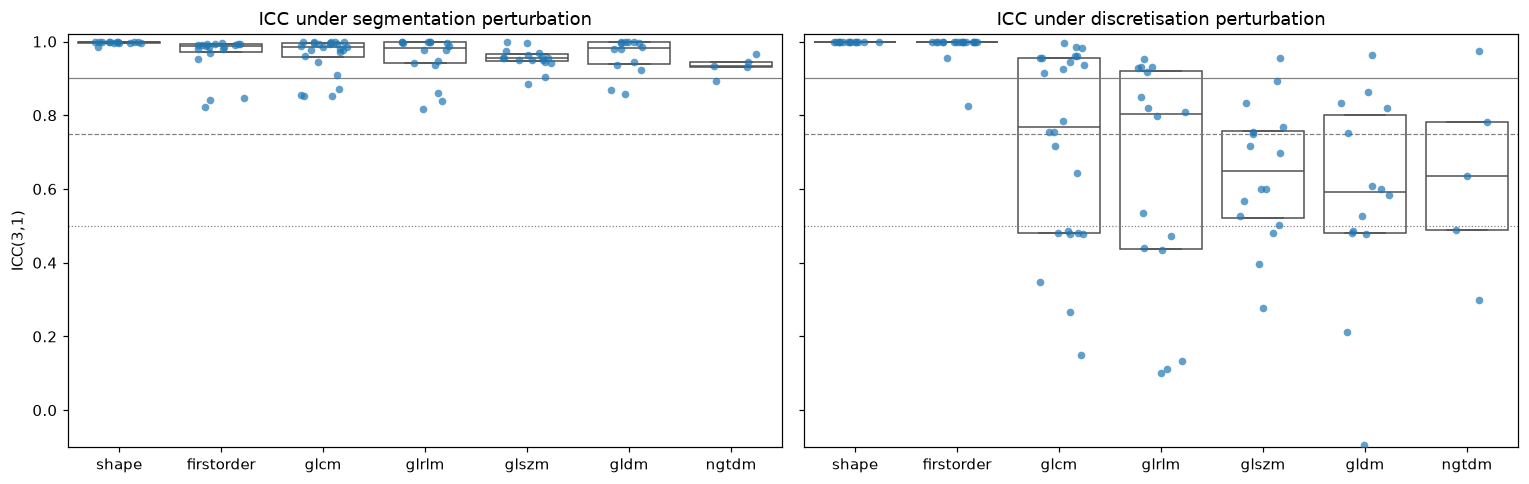

In [5]:
gtv = long[long.ROI == "GTV_Mass"]
icc = pd.DataFrame({
    "segmentation": icc_table(gtv, ["baseline", "erode", "dilate"], FEATS),
    "discretisation": icc_table(gtv, ["baseline", "bw15", "bw40"], FEATS),
})
icc["class"] = [f.split("_")[1] for f in icc.index]
icc["min_icc"] = icc[["segmentation", "discretisation"]].min(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
order = ["shape", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]
for ax, col in zip(axes, ["segmentation", "discretisation"]):
    sns.stripplot(data=icc, x="class", y=col, order=order, ax=ax, size=5, alpha=.7, jitter=.25)
    sns.boxplot(data=icc, x="class", y=col, order=order, ax=ax, showfliers=False,
                boxprops=dict(facecolor="none"), whis=0)
    for t, ls in [(0.9, "-"), (0.75, "--"), (0.5, ":")]:
        ax.axhline(t, color="grey", lw=.8, ls=ls)
    ax.set_title(f"ICC under {col} perturbation"); ax.set_xlabel(""); ax.set_ylim(-0.1, 1.02)
axes[0].set_ylabel("ICC(3,1)")
plt.tight_layout()

ROBUST_T = 0.90
robust = icc.index[icc.min_icc >= ROBUST_T].tolist()
print(f"Robust features (ICC >= {ROBUST_T} for both perturbations): {len(robust)} / {len(FEATS)}")
icc.loc[robust].groupby("class").size().reindex(order, fill_value=0).to_frame("n robust").T

**What the output shows:** each dot is one feature; the lines mark ICC = 0.9 (solid), 0.75 (dashed), 0.5 (dotted).
- **Left (segmentation):** almost every feature survives a 1 mm change of the contour (ICC > 0.9). The tumours are
  large compared with 1 mm, so moving the border changes the values a little but keeps the patients in the same
  order.
- **Right (discretisation):** this is the real filter. Shape features are not affected at all (they ignore
  intensities, so ICC = 1) and most `firstorder` features stay stable, but many texture features (`glrlm`,
  `glszm`, `gldm`, `ngtdm`) depend strongly on the bin width: they count *how many* grey levels, runs or zones
  exist, and that number changes with the bin width.
- The table gives, per class, how many features pass **both** tests: **46 / 107**, i.e. all 14 shape, 14/18
  first-order, 10/24 GLCM and only a handful of the other texture classes. Only these 46 go further. The ICC table is saved
  to `outputs/feature_robustness.csv` (next cell) so the choice is documented.

This is an **unsupervised** filter (it never looks at the outcome), so applying it to all 51 patients before the
model does not leak information about the label.

In [6]:
icc.sort_values("min_icc").to_csv(OUT / "feature_robustness.csv")
print("least robust features:")
icc.sort_values("min_icc")[["class", "segmentation", "discretisation"]].head(8).round(3)

least robust features:


,class,segmentation,discretisation
original_gldm_DependenceNonUniformityNormalized,gldm,0.997,-0.094
original_glrlm_RunVariance,glrlm,0.999,0.100
original_glrlm_LongRunLowGrayLevelEmphasis,glrlm,0.816,0.112
original_glrlm_LongRunEmphasis,glrlm,0.998,0.132
original_glcm_ClusterProminence,glcm,0.962,0.149
original_gldm_SmallDependenceHighGrayLevelEmphasis,gldm,0.979,0.213
original_glcm_ClusterShade,glcm,0.943,0.267
original_glszm_LargeAreaLowGrayLevelEmphasis,glszm,0.970,0.278


**What the output shows:** the 8 least stable features. All of them are fine under the contour perturbation
(segmentation ICC > 0.8) but collapse when the bin width changes (discretisation ICC < 0.3). Values near 0 or
negative mean the perturbation changes
the feature more than the feature differs between patients: it is basically **noise** for our purpose and should
not be used, whatever the outcome analysis says.

## 3. Redundancy: many features say the same thing

Radiomic features are heavily correlated. Many of them are, in practice, another measure of **tumour size**.
With 19 events we cannot afford dozens of near-duplicate variables, so we:
1. compute the Spearman correlation between all robust features (on the patients, baseline condition);
2. group features with |ρ| > 0.9 (hierarchical clustering);
3. keep **one representative per group**, the one with the highest ICC (again: no outcome used).

46 robust features -> 19 clusters (one representative each)
15 robust features have |rho| > 0.8 with tumour volume


Text(0.5, 1.01, 'Correlation between robust features (blocks = redundant groups)')

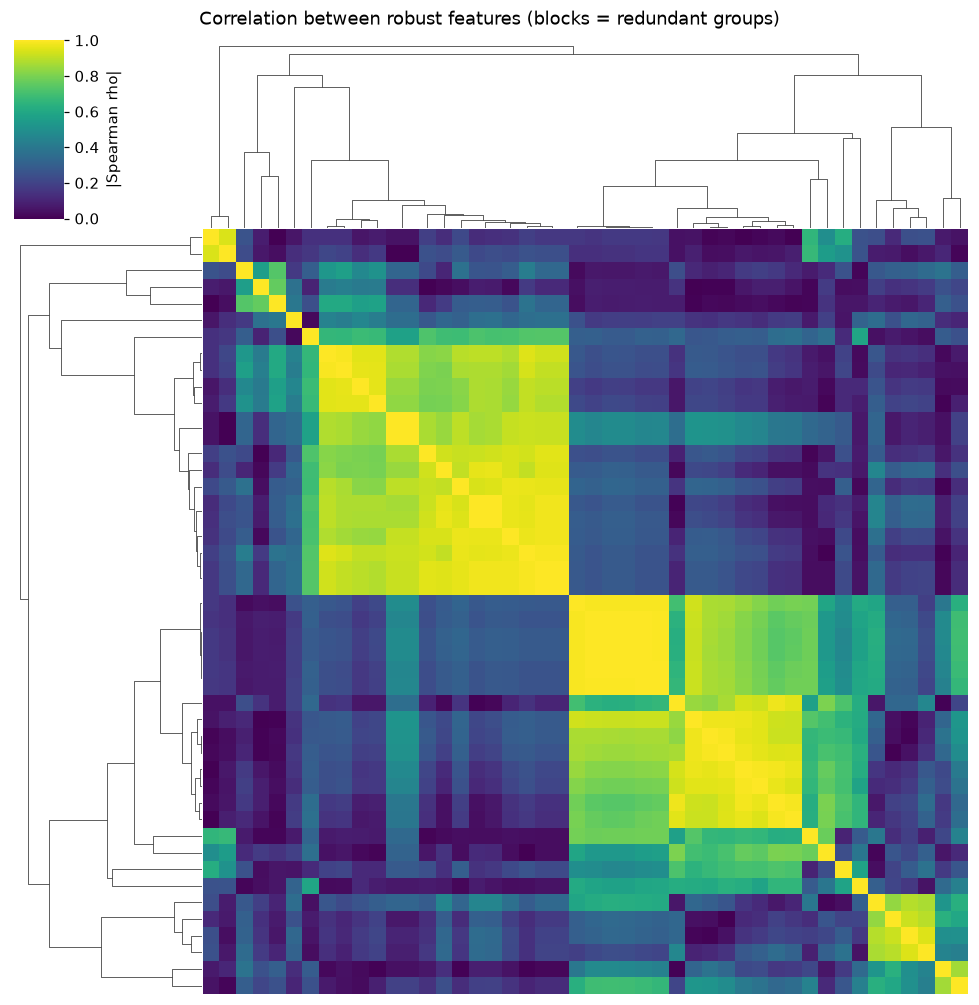

In [7]:
X_rob = base[robust]
rho = X_rob.corr(method="spearman").abs().fillna(0)
dist = squareform(1 - rho.values, checks=False)
clusters = fcluster(linkage(dist, method="average"), t=0.1, criterion="distance")
cl = pd.DataFrame({"cluster": clusters, "icc": icc.loc[robust, "min_icc"]}, index=robust)
reps = cl.sort_values("icc", ascending=False).groupby("cluster").head(1).index.tolist()

vol = "original_shape_MeshVolume"
vol_rho = X_rob.corrwith(base[vol], method="spearman").abs()
print(f"{len(robust)} robust features -> {len(reps)} clusters (one representative each)")
print(f"{(vol_rho > 0.8).sum()} robust features have |rho| > 0.8 with tumour volume")

g = sns.clustermap(rho, cmap="viridis", vmin=0, vmax=1, figsize=(9, 9), xticklabels=False, yticklabels=False,
                   row_linkage=linkage(dist, "average"), col_linkage=linkage(dist, "average"),
                   cbar_kws={"label": "|Spearman rho|"})
g.fig.suptitle("Correlation between robust features (blocks = redundant groups)", y=1.01)

**What the output shows:**
- The heatmap is the correlation matrix, reordered so that similar features sit next to each other. **Bright
  square blocks** are groups of features that carry the same information.
- The printed numbers say how far the feature set can be compressed (**46 robust features → 19 groups**) and how
  many features are essentially "tumour size in disguise" (**15** have |ρ| > 0.8 with volume). That is why the model in section 5 is always compared
  with **volume alone**: a radiomic model is only interesting if it beats size.

In [8]:
reps_df = pd.DataFrame({
    "class": [r.split("_")[1] for r in reps],
    "ICC (min)": icc.loc[reps, "min_icc"].round(3).values,
    "|rho| with volume": vol_rho[reps].round(2).values,
    "cluster size": cl.cluster.value_counts().loc[cl.loc[reps, "cluster"]].values,
}, index=[r.split("_", 2)[2] for r in reps]).sort_values("cluster size", ascending=False)
reps_df

,class,ICC (min),|rho| with volume,cluster size
Maximum2DDiameterSlice,shape,1.000,0.96,9
InterquartileRange,firstorder,0.994,0.28,8
ShortRunEmphasis,glrlm,0.951,0.26,6
Maximum3DDiameter,shape,1.000,0.91,4
Imc2,glcm,0.984,0.20,3
TotalEnergy,firstorder,0.993,0.92,2
Median,firstorder,0.991,0.24,2
Flatness,shape,0.998,0.32,1
RootMeanSquared,firstorder,0.994,0.03,1
90Percentile,firstorder,0.996,0.03,1


**What the output shows:** the reduced feature set, one row per cluster. `cluster size` says how many robust
features that representative stands for. The biggest group (9 features, represented by `Maximum2DDiameterSlice`)
is the **size** group; the second (8 features, `InterquartileRange`) gathers measures of the **spread of HU values**.
Many representatives are alone in their cluster: they carry information not shared by the others. This list is the **input of the statistical analysis**.

## 4. Univariate analysis: does one feature alone separate the groups?

For each representative feature we compute:
- **AUC**: probability that a random patient *with* lung mets has a higher value than a random patient *without*.
  0.5 = no information; values below 0.5 mean "lower in the metastatic group" (we show it as is, so the direction
  is visible).
- **Mann–Whitney p-value**, then the **Benjamini–Hochberg** correction (*q*-value), because testing many features
  at once produces "significant" results by chance (with 20 tests at p < 0.05 we expect ≈ 1 false positive).

In [9]:
y = data.LungMets.values
rows = []
for f in reps:
    x = data[f].values
    rows.append({"feature": f.split("_", 2)[2], "class": f.split("_")[1], "AUC": roc_auc_score(y, x),
                 "p": mannwhitneyu(x[y == 1], x[y == 0]).pvalue, "col": f})
uni = pd.DataFrame(rows)
uni["q (BH)"] = false_discovery_control(uni.p, method="bh")
uni = uni.reindex((uni.AUC - 0.5).abs().sort_values(ascending=False).index)
uni.drop(columns="col").round(3).head(10)

,feature,class,AUC,p,q (BH)
10,Imc2,glcm,0.316,0.030,0.305
8,TotalEnergy,firstorder,0.664,0.053,0.305
13,Imc1,glcm,0.658,0.063,0.305
0,Maximum2DDiameterSlice,shape,0.657,0.064,0.305
16,LargeAreaHighGrayLevelEmphasis,glszm,0.630,0.126,0.348
12,Skewness,firstorder,0.628,0.131,0.348
3,Elongation,shape,0.625,0.141,0.348
1,Maximum3DDiameter,shape,0.623,0.147,0.348
2,Flatness,shape,0.576,0.375,0.733
5,Sphericity,shape,0.574,0.386,0.733


**What the output shows:** the features ranked by how strongly they separate the two groups. Look at the
**q-value**, not the raw p: q < 0.05 means the association is unlikely to be a multiple-testing accident.
- The best features reach AUC ≈ 0.66 (or 0.32 for `Imc2`, i.e. 0.68 in the "lower in metastatic patients"
  direction), with raw p between 0.03 and 0.06.
- After correction for 19 tests, **no feature is significant** (all q > 0.3). With 51 patients, an AUC of 0.6–0.65
  is within what chance can produce.
- Note that two of the top features (`TotalEnergy`, `Maximum2DDiameterSlice`) belong to the **size** group: larger
  tumours metastasise more often, a well-known clinical fact.

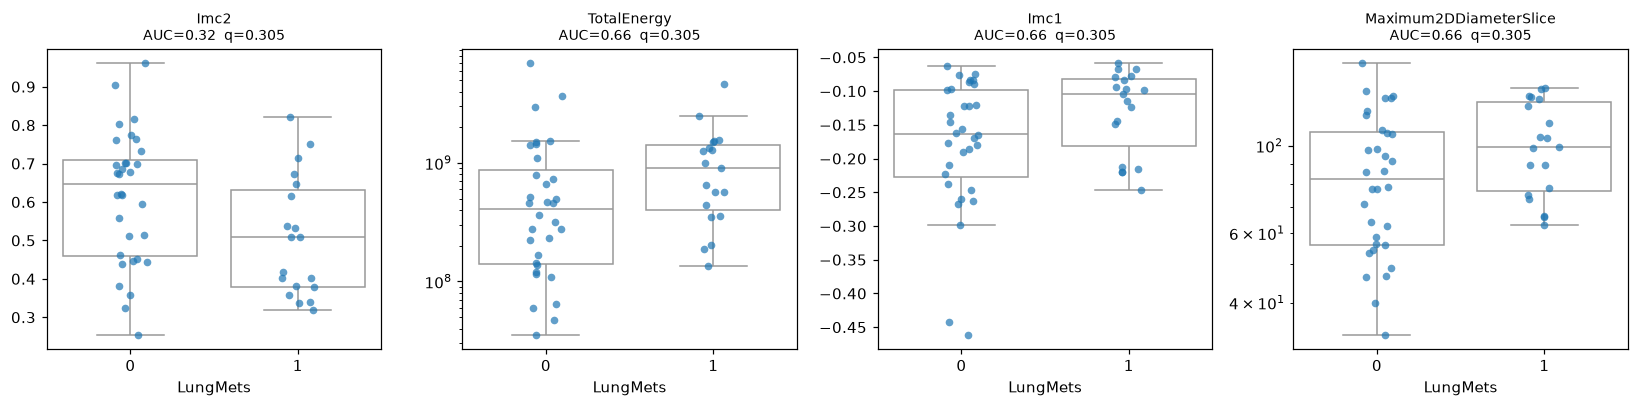

In [10]:
top = uni.head(4)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (_, r) in zip(axes, top.iterrows()):
    sns.boxplot(x=data.LungMets, y=data[r.col], ax=ax, showfliers=False, color="white")
    sns.stripplot(x=data.LungMets, y=data[r.col], ax=ax, size=5, alpha=.7)
    ax.set_title(f"{r.feature}\nAUC={r.AUC:.2f}  q={r['q (BH)']:.3f}", fontsize=9)
    ax.set_xlabel("LungMets"); ax.set_ylabel("")
    if r["class"] == "shape" or data[r.col].min() > 0 and data[r.col].max() / data[r.col].min() > 50:
        ax.set_yscale("log")
plt.tight_layout()

**What the output shows:** the raw values of the 4 most discriminant features, per group (0 = no lung mets,
1 = lung mets). Each dot is a patient. Even for the best features the two clouds **overlap a lot**: no single
feature is a reliable test on its own.

## 5. Multivariable model, evaluated honestly

### Design
- **Model:** logistic regression (L2-regularised, `class_weight="balanced"` for the 19/32 imbalance). Simple and
  interpretable, appropriate for 51 patients.
- **Pipeline inside each fold:** Yeo–Johnson transform (makes skewed features more Gaussian and scales them) →
  keep the **k = 2** features most associated with the label (`SelectKBest`) → logistic regression.
  The selection is done **inside** the cross-validation: choosing features on all patients and then
  cross-validating is a classic leak that inflates the AUC.
- **Evaluation:** 5-fold stratified cross-validation, **repeated 50 times** with different splits → a distribution
  of AUCs (one split of 51 patients is too noisy to trust).
- **Baselines:** tumour **volume alone** and **grade** (clinical). The radiomic model must beat them to be
  interesting.
- **Permutation test:** we shuffle the labels 300 times and redo the cross-validation. If the real AUC is not
  better than most shuffled AUCs, the model has learned nothing.

In [11]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=50, random_state=0)

def model(k=None):
    steps = [PowerTransformer()]
    if k: steps.append(SelectKBest(f_classif, k=k))
    steps.append(LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
    return make_pipeline(*steps)

grade_num = data.Grade.map({"Low": 0, "Intermediate": 1, "High": 2})
ok = grade_num.notna()           # 3 patients have no grade
sets = {
    "volume only": (data[[vol]], model()),
    "grade only (n=48)": (grade_num[ok].to_frame(), model()),
    "radiomics (k=2 of reps)": (data[reps], model(k=2)),
    "radiomics + volume (k=2)": (data[sorted(set(reps) | {vol})], model(k=2)),
}
results = {}
for name, (X, mdl) in sets.items():
    yy = data.LungMets.loc[X.index].values
    results[name] = cross_val_score(mdl, X.values, yy, cv=cv, scoring="roc_auc")
res = pd.DataFrame(results)
summary = res.agg(["mean", "std"]).T.round(3)
summary["5th pct"] = res.quantile(.05).round(3); summary["95th pct"] = res.quantile(.95).round(3)
summary.to_csv(OUT / "model_cv_auc.csv")
summary

,mean,std,5th pct,95th pct
volume only,0.697,0.155,0.422,0.917
grade only (n=48),0.633,0.140,0.417,0.833
radiomics (k=2 of reps),0.501,0.152,0.250,0.750
radiomics + volume (k=2),0.534,0.151,0.292,0.762


**What the output shows:** for each feature set, the mean AUC over the 250 test folds (5 folds × 50 repeats),
its standard deviation and the 5th–95th percentile range. Read it like this: **mean ≈ 0.5** means no better than a
coin flip, and the **spread** shows how much the result depends on which patients land in the test fold (with
~10 patients per test fold, one fold's AUC can swing by ±0.2).

**Result:**
- **Tumour volume alone: AUC ≈ 0.70.** This is the strongest predictor here.
- Grade alone: ≈ 0.63.
- **Radiomics model: ≈ 0.50**, i.e. chance. Adding volume to the candidates does not help much (≈ 0.53), because
  the selection step often picks other features instead of volume.

So, on this dataset, **CT texture of the primary tumour does not add anything to its size** for predicting lung
metastases. This is a negative but useful result: it shows the evaluation protocol is strict enough not to
"find" a signal that is not there.

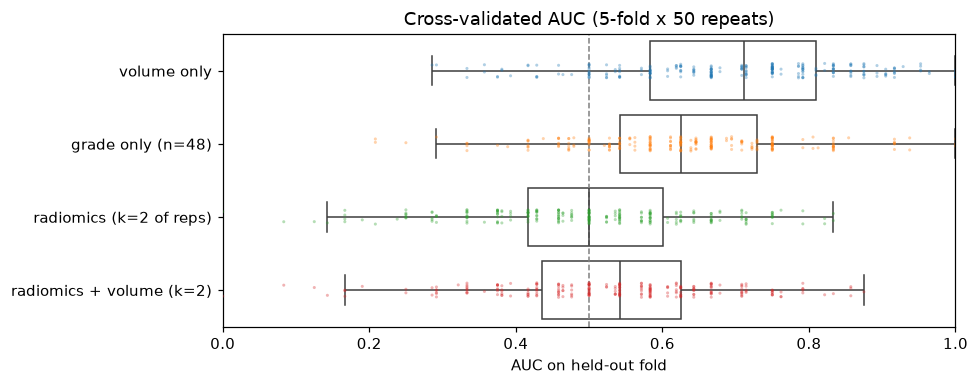

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.boxplot(data=res, orient="h", ax=ax, color="white", showfliers=False)
sns.stripplot(data=res, orient="h", ax=ax, size=2, alpha=.35)
ax.axvline(.5, color="grey", ls="--", lw=1); ax.set_xlabel("AUC on held-out fold"); ax.set_xlim(0, 1)
ax.set_title("Cross-validated AUC (5-fold x 50 repeats)")
plt.tight_layout()

**What the output shows:** the same numbers as a picture. Each small dot is the AUC on one test fold; the box
is the middle 50 %. The dashed line is chance (0.5).

radiomics model: AUC = 0.575, permutation p = 0.282


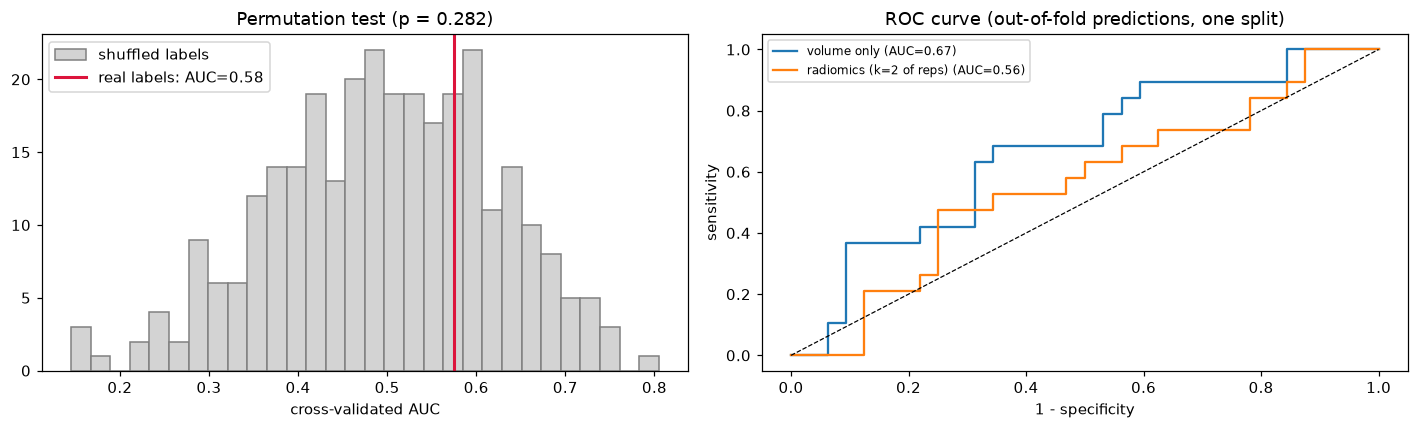

In [13]:
X_r, mdl_r = sets["radiomics (k=2 of reps)"]
score, perm_scores, pval = permutation_test_score(
    mdl_r, X_r.values, y, cv=StratifiedKFold(5, shuffle=True, random_state=1),
    scoring="roc_auc", n_permutations=300, random_state=0, n_jobs=-1)
print(f"radiomics model: AUC = {score:.3f}, permutation p = {pval:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(perm_scores, bins=30, color="lightgrey", edgecolor="grey", label="shuffled labels")
axes[0].axvline(score, color="crimson", lw=2, label=f"real labels: AUC={score:.2f}")
axes[0].set_xlabel("cross-validated AUC"); axes[0].legend(); axes[0].set_title(f"Permutation test (p = {pval:.3f})")

for name in ["volume only", "radiomics (k=2 of reps)"]:
    X, mdl = sets[name]
    proba = cross_val_predict(mdl, X.values, y, cv=StratifiedKFold(5, shuffle=True, random_state=1), method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, proba):.2f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8)
axes[1].set_xlabel("1 - specificity"); axes[1].set_ylabel("sensitivity"); axes[1].legend(fontsize=8)
axes[1].set_title("ROC curve (out-of-fold predictions, one split)")
plt.tight_layout()

**What the output shows:**
- **Left:** the grey histogram is what the model achieves when the labels are random (pure chance, given 51
  patients). The red line is the real result. The **p-value** is the fraction of shuffled runs that did at least
  as well. p < 0.05 would mean the model captures something beyond chance; here the real AUC sits inside the
  shuffled distribution, which confirms that the radiomic model has not learned a real signal.
- **Right:** ROC curves built from out-of-fold predictions (each patient is predicted by a model that never saw it).
  The closer to the top-left corner, the better. The diagonal is chance. The volume curve stays above the
  radiomics curve over most of the range.

In [14]:
# Which features does the selection step pick, across all folds? (stability of the selection)
picked = []
for tr, _ in RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0).split(X_r, y):
    m_ = model(k=2).fit(X_r.values[tr], y[tr])
    picked += list(np.array(reps)[m_.named_steps["selectkbest"].get_support()])
freq = pd.Series(picked).value_counts() / 100
freq.index = [i.split("_", 2)[2] for i in freq.index]
freq.head(8).rename("selection frequency").to_frame()

,selection frequency
Imc2,0.55
TotalEnergy,0.36
Imc1,0.33
Maximum2DDiameterSlice,0.21
Elongation,0.17
Skewness,0.11
Flatness,0.11
LargeAreaHighGrayLevelEmphasis,0.08


**What the output shows:** how often each feature was selected over the 100 training folds (k = 2, so the
frequencies sum to 2). A feature picked in ~100 % of folds is a **stable** choice; here the most frequent one
(`Imc2`) is picked in only about half of the folds and the rest is spread over many features. The "signature"
changes with the training patients: it is **not reproducible**, which explains the chance-level AUC.

## 6. Interpretation and link to STEREOSARC

### What this notebook establishes (the method)
- A reproducible **robustness filter**: ICC under contour and discretisation perturbations, saved in
  `outputs/feature_robustness.csv`.
- A **redundancy reduction** that does not look at the outcome.
- An **evaluation protocol** that avoids the usual leaks (selection inside CV, repeated CV, volume baseline,
  permutation test). The same code will run on the Baclesse data.

### What it does *not* establish (the result)
- On this dataset, volume (AUC ≈ 0.70) beats every CT radiomic model (≈ 0.50); no single feature survives the
  multiple-testing correction.
- 51 patients / 19 events is very small; the confidence intervals are wide.
- We only use the **CT of a PET/CT** (low-dose, no contrast). Vallières et al. (2015) reached high AUCs by combining
  **FDG-PET and MRI** texture; CT alone is expected to be weaker, which is consistent with what we see here.
- The QC showed **two reconstruction kernels**; with a larger, multi-scanner cohort a harmonisation step will be
  needed.

### Differences with the STEREOSARC question
| | Public dataset (here) | STEREOSARC (Baclesse) |
|---|---|---|
| Images | 1 pre-treatment PET/CT per patient | ~300 **follow-up** CTs, several per patient |
| ROI | the primary tumour | **non-irradiated** tissue (irradiated lesions must be *excluded*) |
| Question | does the primary tumour predict lung mets? | do subtle changes **over time** precede new metastases? |
| Natural analysis | one row per patient | **delta-radiomics** (change between consecutive scans), survival-type models |

### Next steps
1. Robustness with more perturbations (small rotations/translations, noise, resampling 1 vs 2 mm) → closer to
   test–retest.
2. Kernel harmonisation (ComBat) and check how the ICC / AUC change.
3. Prepare the **exclusion masks** (step 3 of the pipeline): build them from RTSTRUCT of irradiated lesions + margin,
   and test on this dataset by excluding `GTV_Mass` and analysing the surrounding tissue / the edema ring.
4. Once the Baclesse data format is known: longitudinal loader (patient → list of dated scans).